# Bisaya Post-Class Multimodal Affect Recognition (Audio + Face)
**Group 1 - First-Year CS students - pilot (n = 30)**

Pipeline: metadata -> exploratory analysis -> audio features + spectrogram embeddings -> face features from video -> unimodal and fused models -> participant-independent evaluation -> permutation test -> lexically controlled analysis.

**Design rules**
- The reference label is always the participant's **self-reported** valence/arousal, never a model's or researcher's reading of the face or voice.
- Evaluation is leave-one-participant-out, so no participant appears in both training and testing.
- Spoken word, year level, activity, and session are NOT predictors.
- **Privacy:** raw video frames are processed in memory and never saved. Only numeric facial features (blendshape scores) are stored. Do not put participant faces in the report or in any shared file unless your consent form and ethics approval explicitly allow it.
- The audio-only results (RQ4) are still reported on their own. Face is an added modality, not a replacement.

## Protocol compliance and scope (read before running)
This notebook follows the CS412 Research Mini-Project sheet. Points that matter:

1. **Primary analysis = speech only (Sections XIV-XVI).** The sheet defines the primary input as acoustic and prosodic features and the reference as self-reported affect. Audio-only results are reported separately (RQ4, RQ5).
2. **Face video is an extension, not in the sheet.** The sheet's consent list mentions voice recording only, and the data table (Section XI) has no video variable. Use the face results only if your approved protocol and signed consent forms explicitly cover video recording of faces, and your instructor agrees. Otherwise drop the face blocks and report audio only.
3. **Identity must not appear in the dataset or report (Section VI).** Raw videos stay in the private `video/` folder and are never shared or submitted with the dataset. Only numeric features are saved. No faces in figures.
4. **Minimum 40 valid observations (Section XVIII).** The check below reports whether you reached it.
5. **Spoken word, year level, activity, and session are never predictors (Section XV).**
6. **Participant-independent evaluation (Section XVI)**: leave-one-participant-out.
7. **Session boundary** (Morning vs Afternoon-Evening) must have been defined before collection; record it in the config cell.

In [4]:
%pip install opencv-python mediapipe librosa scikit-learn matplotlib pillow torch torchvision seaborn pandas numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
# !pip install librosa numpy pandas scikit-learn matplotlib pillow torch torchvision seaborn opencv-python mediapipe
import urllib.request
import warnings
from pathlib import Path
import cv2
import librosa
import matplotlib
import matplotlib.pyplot as plt
import mediapipe as mp
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torchvision.models as models
import torchvision.transforms as T
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision
from PIL import Image
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEED = 42
np.random.seed(SEED)

## 1. Configuration

In [5]:
AUDIO_DIR = Path("audio")
VIDEO_DIR = Path("video")
METADATA_CSV = Path("GROUP 1_Metadata.csv")
OUT_DIR = Path("RESULTS")
IMG_DIR = OUT_DIR / "SPECTROGRAMS"
MODEL_DIR = Path("models")
for d in [OUT_DIR, IMG_DIR, MODEL_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# ---- audio ----
SR = 16000
CLIP_SEC = 1.5
N_MELS = 128
IMG_SIZE = 224

# ---- face ----
FACE_FPS = 10            # frames analysed per second of video
MIN_DETECTION_RATE = 0.5 # videos below this are flagged in the QC table
VIDEO_EXTS = [".mp4", ".mov", ".avi", ".mkv", ".webm"]

# ---- modelling ----
N_PCA = 5                # PCA components PER modality block (keep small for n=30)
N_PERM = 100             # permutation-test repeats

# ---- protocol requirements (project sheet) ----
MIN_VALID = 40           # Section XVIII: minimum valid observations per group
ASSIGNED_YEAR = "1st Year"   # Group 1 is assigned first-year CS students
# Session boundary (Morning vs Afternoon-Evening) must be defined BEFORE data collection
# and used by all groups. Write the agreed boundary here for your report:
SESSION_BOUNDARY_NOTE = "e.g. Morning = classes ending before 12:00 PM; Afternoon-Evening = 12:00 PM onward"

# metadata.csv column names (edit if yours differ)
COL_FILE = "Audio Filename"
COL_VAL = "Valence"
COL_ARO = "Arousal"
COL_VIDEO = "Video Filename"     # optional; if missing, same name as the WAV with a video extension
COL_VSTART = "Video Start (s)"   # optional: start of the spoken word in the video
COL_VEND = "Video End (s)"       # optional: end of the spoken word in the video

VAL_THRESHOLD = 3   # valence 4-5 = positive
ARO_THRESHOLD = 3   # arousal 4-5 = high

## 2. Load metadata and create labels

In [6]:
df = pd.read_csv(METADATA_CSV)
raw_meta = df.copy()
df = df.rename(columns={COL_FILE: "file", COL_VAL: "valence", COL_ARO: "arousal"})
stem = df["file"].str.replace(".wav", "", regex=False)
parts = stem.str.split("_")
df["participant"] = parts.str[0]
df["word"] = parts.str[-1]
df["path"] = df["file"].apply(lambda f: str(AUDIO_DIR / f))
df["valence_class"] = np.where(df["valence"] > VAL_THRESHOLD, "positive", "non-positive")
df["arousal_class"] = np.where(df["arousal"] > ARO_THRESHOLD, "high", "low-mod")


def find_video(row_idx):
    if COL_VIDEO in raw_meta.columns and pd.notna(raw_meta.loc[row_idx, COL_VIDEO]):
        p = VIDEO_DIR / str(raw_meta.loc[row_idx, COL_VIDEO])
        return str(p) if p.exists() else None
    base = Path(df.loc[row_idx, "file"]).stem
    for ext in VIDEO_EXTS:
        p = VIDEO_DIR / (base + ext)
        if p.exists():
            return str(p)
    return None


df["video_path"] = [find_video(i) for i in df.index]
df["v_start"] = raw_meta[COL_VSTART] if COL_VSTART in raw_meta.columns else np.nan
df["v_end"] = raw_meta[COL_VEND] if COL_VEND in raw_meta.columns else np.nan

print("Missing audio:", [p for p in df["path"] if not Path(p).exists()])
df = df[df["path"].apply(lambda p: Path(p).exists())].reset_index(drop=True)
print("Recordings without a matching video:", int(df["video_path"].isna().sum()))
print(len(df), "recordings |", df["participant"].nunique(), "participants")
print(df["valence_class"].value_counts(), "\n")
print(df["arousal_class"].value_counts(), "\n")
print(df["word"].value_counts())

Missing audio: []
Recordings without a matching video: 0
30 recordings | 30 participants
valence_class
non-positive    18
positive        12
Name: count, dtype: int64 

arousal_class
low-mod    20
high       10
Name: count, dtype: int64 

word
Kapoy      13
Sayon       3
Lisod       3
Lingaw      3
Salamat     3
Grabe       3
Libog       2
Name: count, dtype: int64


### 2b. Metadata validation (Sections XI and XII)
Checks coded metadata and file naming against the sheet: filename pattern `ParticipantCode_YearLevel_Session_Word.wav`, allowed words and activities, 1-5 ratings, year and session consistency, duplicate participants, and the 40-observation minimum.

In [7]:
import re

WORDS = ["Salamat", "Ambot", "Grabe", "Lisod", "Sayon", "Lingaw", "Kapoy", "Libog"]
ACTIVITIES = ["Lecture/Discussion", "Laboratory Activity", "Programming/Coding Activity", "Quiz", "Examination",
              "Presentation/Reporting", "Group Activity", "Recitation", "Project/Practical Activity", "Other"]
YEAR_MAP = {"Y1": "1st Year", "Y2": "2nd Year", "Y3": "3rd Year", "Y4": "4th Year"}
SESSION_MAP = {"AM": "Morning", "PM": "Afternoon-Evening"}
NAME_RE = re.compile(r"^(Y[1-4])-(\d{3})_(Y[1-4])_(AM|PM)_(" + "|".join(WORDS) + r")\.wav$")

# Ensure raw_meta exists even if this cell is run before the metadata-loading cell
if "raw_meta" not in globals():
    raw_meta = pd.read_csv(METADATA_CSV)

meta_idx = raw_meta.rename(columns={COL_FILE: "file"}).set_index("file")
issues = []
for _, r in df.iterrows():
    f = r["file"]
    m = NAME_RE.match(f)
    if not m:
        issues.append((f, "filename does not follow ParticipantCode_YearLevel_Session_Word.wav (or word not in list)"))
        continue
    code_year, _, name_year, ses, word = m.groups()
    if code_year != name_year:
        issues.append((f, "year in participant code and in filename differ"))
    if YEAR_MAP[name_year] != ASSIGNED_YEAR:
        issues.append((f, f"year is {YEAR_MAP[name_year]}, group is assigned {ASSIGNED_YEAR}"))
    row = meta_idx.loc[f]
    if "Year Level" in meta_idx.columns and row["Year Level"] != YEAR_MAP[name_year]:
        issues.append((f, "Year Level column does not match filename"))
    if "Session" in meta_idx.columns and row["Session"] != SESSION_MAP[ses]:
        issues.append((f, "Session column does not match AM/PM in filename"))
    if "Spoken Word" in meta_idx.columns and row["Spoken Word"] != word:
        issues.append((f, "Spoken Word column does not match filename"))
    if "Class Activity" in meta_idx.columns and row["Class Activity"] not in ACTIVITIES:
        issues.append((f, f"Class Activity '{row['Class Activity']}' is not an allowed category"))
    for col in ["valence", "arousal"]:
        v = r[col]
        if pd.isna(v) or v not in [1, 2, 3, 4, 5]:
            issues.append((f, f"{col} must be a whole number 1-5 (found {v})"))

dups = df["participant"][df["participant"].duplicated()].unique().tolist()
if dups:
    issues.append(("(multiple)", f"participants with more than one recording: {dups} "
                                 "(allowed only if your approved design permits repeated observations)"))

print(f"Valid-looking observations: {len(df)} (required minimum: {MIN_VALID})")
if len(df) < MIN_VALID:
    print(f"WARNING: {MIN_VALID - len(df)} observations short of the minimum. State this and the reason in your limitations.")
if issues:
    print(f"\n{len(issues)} issue(s) to fix:")
    display(pd.DataFrame(issues, columns=["file", "issue"]))
else:
    print("Metadata and filenames follow the protocol.")
print("\nSession boundary used:", SESSION_BOUNDARY_NOTE)

Valid-looking observations: 30 (required minimum: 40)
Metadata and filenames follow the protocol.

Session boundary used: e.g. Morning = classes ending before 12:00 PM; Afternoon-Evening = 12:00 PM onward


## 3. Exploratory analysis (Section XIII: context x affect)
Done before any modelling, as the project sheet requires. All 40 participants are first-year, so Year Level has a single value in this group; it becomes comparable only after the class datasets are pooled.

,valence,arousal
count,30.00,30.00
mean,3.20,2.80
std,0.92,1.24
min,1.00,1.00
25%,3.00,2.00
50%,3.00,3.00
75%,4.00,4.00
max,5.00,5.00


saved: RESULTS\exploratory_rating_distribution.png


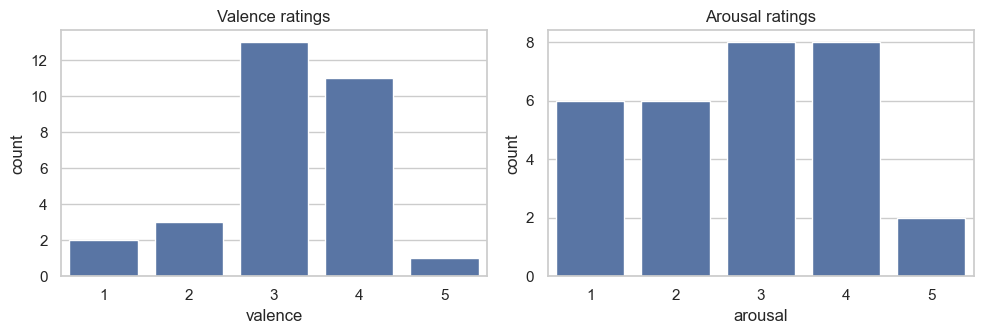


=== Year Level x affect ===


valence            arousal           
             count mean   std   count mean   std
Year Level                                      
1st Year        30  3.2  0.92      30  2.8  1.24

Only one Year Level value in this group, so no comparison is possible yet.

=== Class Activity x affect ===


valence             arousal            
                             count  mean   std   count  mean   std
Class Activity                                                    
Examination                      9  3.22  1.20       9  2.33  1.00
Laboratory Activity              1  2.00   NaN       1  1.00   NaN
Lecture/Discussion               4  2.75  0.50       4  3.00  0.82
Presentation/Reporting           2  4.00  0.00       2  5.00  0.00
Project/Practical Activity       3  3.67  0.58       3  4.00  0.00
Quiz                            11  3.18  0.87      11  2.55  1.21

saved: RESULTS\exploratory_class_activity.png


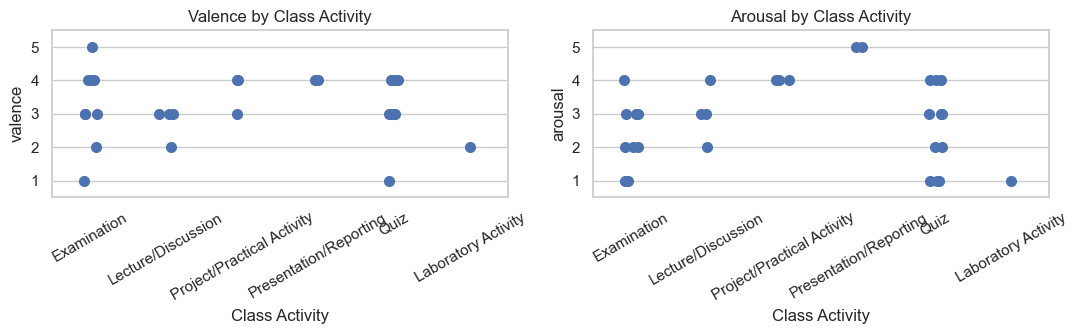


=== Session x affect ===


valence             arousal            
                    count  mean   std   count  mean   std
Session                                                  
Afternoon-Evening      17  3.06  0.97      17  2.41  1.18
Morning                13  3.38  0.87      13  3.31  1.18

saved: RESULTS\exploratory_session.png


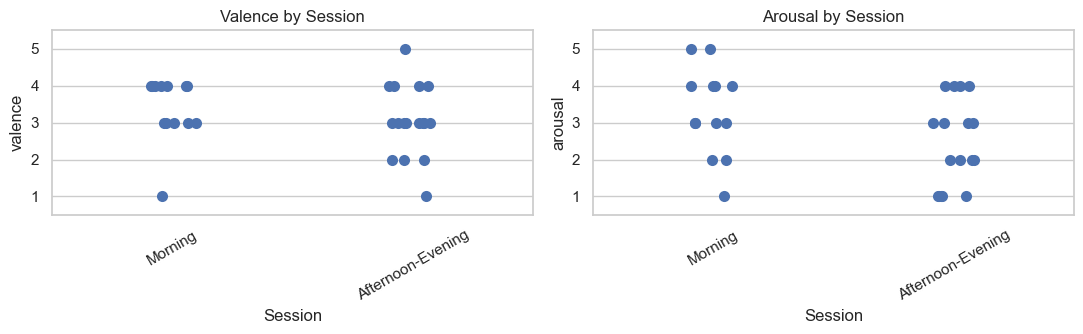


=== word x affect ===


valence             arousal            
          count  mean   std   count  mean   std
word                                           
Grabe         3  3.00  1.00       3  2.67  1.53
Kapoy        13  2.92  1.04      13  2.77  1.09
Libog         2  3.50  0.71       2  2.50  0.71
Lingaw        3  4.33  0.58       3  3.67  1.53
Lisod         3  2.67  0.58       3  2.33  1.15
Salamat       3  3.67  0.58       3  3.67  1.53
Sayon         3  3.33  0.58       3  2.00  1.73

saved: RESULTS\exploratory_word.png


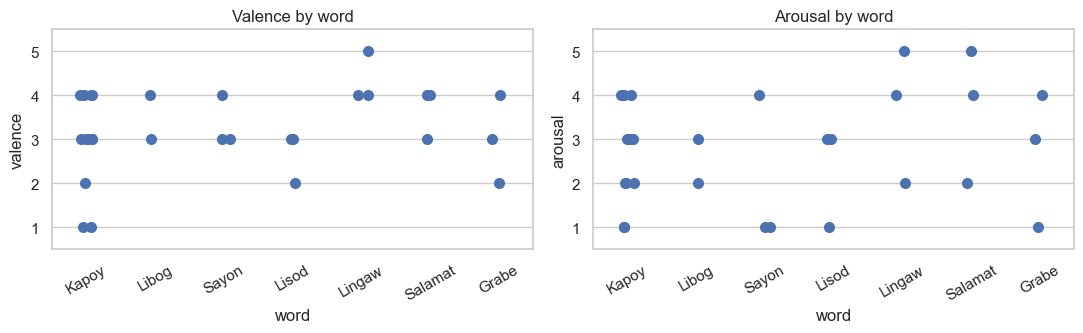


=== Spoken word x Class Activity (counts) ===


word,Grabe,Kapoy,Libog,Lingaw,Lisod,Salamat,Sayon
Class Activity,,,,,,,
Examination,0,3,2,1,2,0,1
Laboratory Activity,1,0,0,0,0,0,0
Lecture/Discussion,1,3,0,0,0,0,0
Presentation/Reporting,0,0,0,1,0,1,0
Project/Practical Activity,0,2,0,1,0,0,0
Quiz,1,5,0,0,1,2,2


In [8]:
# ---- where the files are saved ----
RESULTS_DIR = Path("RESULTS")      # the "outputs" folder; change to Path("results") if you prefer
RESULTS_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(fig, name):
    path = RESULTS_DIR / f"{name}.png"
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print("saved:", path)


raw_idx = raw_meta.rename(columns={COL_FILE: "file"}).set_index("file")
CONTEXT_COLS = ["Year Level", "Class Activity", "Session"]
for c in CONTEXT_COLS:
    if c in raw_idx.columns:
        df[c] = df["file"].map(raw_idx[c])

desc = df[["valence", "arousal"]].describe().round(2)
display(desc)
desc.to_csv(RESULTS_DIR / "exploratory_rating_summary.csv")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
sns.countplot(x="valence", data=df, order=[1, 2, 3, 4, 5], ax=axes[0]); axes[0].set_title("Valence ratings")
sns.countplot(x="arousal", data=df, order=[1, 2, 3, 4, 5], ax=axes[1]); axes[1].set_title("Arousal ratings")
plt.tight_layout()
save_fig(fig, "exploratory_rating_distribution")   # save BEFORE plt.show()
plt.show()

for c in CONTEXT_COLS + ["word"]:
    if c not in df.columns:
        continue
    slug = c.lower().replace(" ", "_")
    print(f"\n=== {c} x affect ===")
    tbl = df.groupby(c)[["valence", "arousal"]].agg(["count", "mean", "std"]).round(2)
    display(tbl)
    tbl.to_csv(RESULTS_DIR / f"exploratory_{slug}_summary.csv")
    if df[c].nunique() < 2:
        print(f"Only one {c} value in this group, so no comparison is possible yet.")
        continue
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    for ax, v in zip(axes, ["valence", "arousal"]):
        sns.stripplot(data=df, x=c, y=v, ax=ax, jitter=True, size=8)
        ax.set_ylim(0.5, 5.5); ax.set_title(f"{v.capitalize()} by {c}"); ax.tick_params(axis="x", rotation=30)
    plt.tight_layout()
    save_fig(fig, f"exploratory_{slug}")
    plt.show()

if "Class Activity" in df.columns:
    print("\n=== Spoken word x Class Activity (counts) ===")
    ct = pd.crosstab(df["Class Activity"], df["word"])
    display(ct)
    ct.to_csv(RESULTS_DIR / "exploratory_word_by_activity_counts.csv")

### RQ1: reported affective states
Counts of the participants' own words for how they feel (free text), and where they fall on the valence-arousal grid.

Self-reported feelings (free text):


,count
feeling,
kapoy,12
lingaw,2
grabe,2
lisod,2
libog,1
nagmahay ko kay wala nako nakita ang bonus,1
okay lang,1
galisod,1
gikapoy,1


Valence class x arousal class (counts):


arousal_class,high,low-mod
valence_class,,
non-positive,3,15
positive,7,5


saved: Results\rq1_valence_arousal_scatter.png


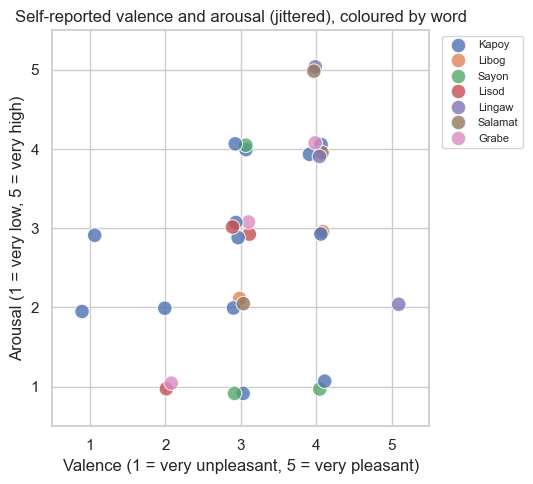

saved: Results\rq1_valence_arousal_counts.png


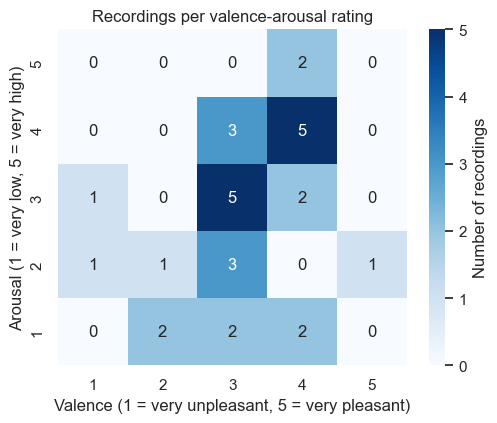

In [12]:
# ===================== RQ1: reported affective states (valence x arousal) =====================
# Saves the figures (PNG) and the tables (CSV) to the Results folder.
# Needs: df, raw_idx (created in the exploratory-analysis cell), SEED, np, pd, plt, sns.

from pathlib import Path

RESULTS_DIR = Path("Results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# ---- free-text feelings ----
if "Self-Reported Feeling" in raw_idx.columns:
    df["feeling"] = df["file"].map(raw_idx["Self-Reported Feeling"]).astype(str).str.strip().str.lower()
    print("Self-reported feelings (free text):")
    feelings = df["feeling"].value_counts().to_frame("count")
    display(feelings)
    feelings.to_csv(RESULTS_DIR / "rq1_self_reported_feelings_counts.csv", encoding="utf-8")

# ---- valence class x arousal class counts ----
print("Valence class x arousal class (counts):")
class_counts = pd.crosstab(df["valence_class"], df["arousal_class"])
display(class_counts)
class_counts.to_csv(RESULTS_DIR / "rq1_valence_class_by_arousal_class_counts.csv", encoding="utf-8")

# ---- scatter of ratings (jittered, so overlapping points stay visible) ----
rng_j = np.random.default_rng(SEED)
fig = plt.figure(figsize=(5.5, 5))
sns.scatterplot(x=df["valence"] + rng_j.uniform(-0.12, 0.12, len(df)),
                y=df["arousal"] + rng_j.uniform(-0.12, 0.12, len(df)),
                hue=df["word"], s=110, alpha=0.8)
plt.xlim(0.5, 5.5); plt.ylim(0.5, 5.5)
plt.xlabel("Valence (1 = very unpleasant, 5 = very pleasant)")
plt.ylabel("Arousal (1 = very low, 5 = very high)")
plt.title("Self-reported valence and arousal (jittered), coloured by word")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
fig.savefig(RESULTS_DIR / "rq1_valence_arousal_scatter.png", dpi=300, bbox_inches="tight")   # save BEFORE plt.show()
print("saved:", RESULTS_DIR / "rq1_valence_arousal_scatter.png")
plt.show()

# ---- exact counts for every valence x arousal rating combination (no overlap problem) ----
grid = (pd.crosstab(df["arousal"], df["valence"])
          .reindex(index=[1, 2, 3, 4, 5], columns=[1, 2, 3, 4, 5], fill_value=0))
grid.to_csv(RESULTS_DIR / "rq1_valence_by_arousal_rating_counts.csv", encoding="utf-8")

fig2 = plt.figure(figsize=(5.2, 4.4))
sns.heatmap(grid.sort_index(ascending=False), annot=True, fmt="d", cmap="Blues", cbar_kws={"label": "Number of recordings"})
plt.xlabel("Valence (1 = very unpleasant, 5 = very pleasant)")
plt.ylabel("Arousal (1 = very low, 5 = very high)")
plt.title("Recordings per valence-arousal rating")
plt.tight_layout()
fig2.savefig(RESULTS_DIR / "rq1_valence_arousal_counts.png", dpi=300, bbox_inches="tight")
print("saved:", RESULTS_DIR / "rq1_valence_arousal_counts.png")
plt.show()

## 4. Audio features

Handcrafted audio features: (30, 67)
saved: Results\spectrogram_examples.png


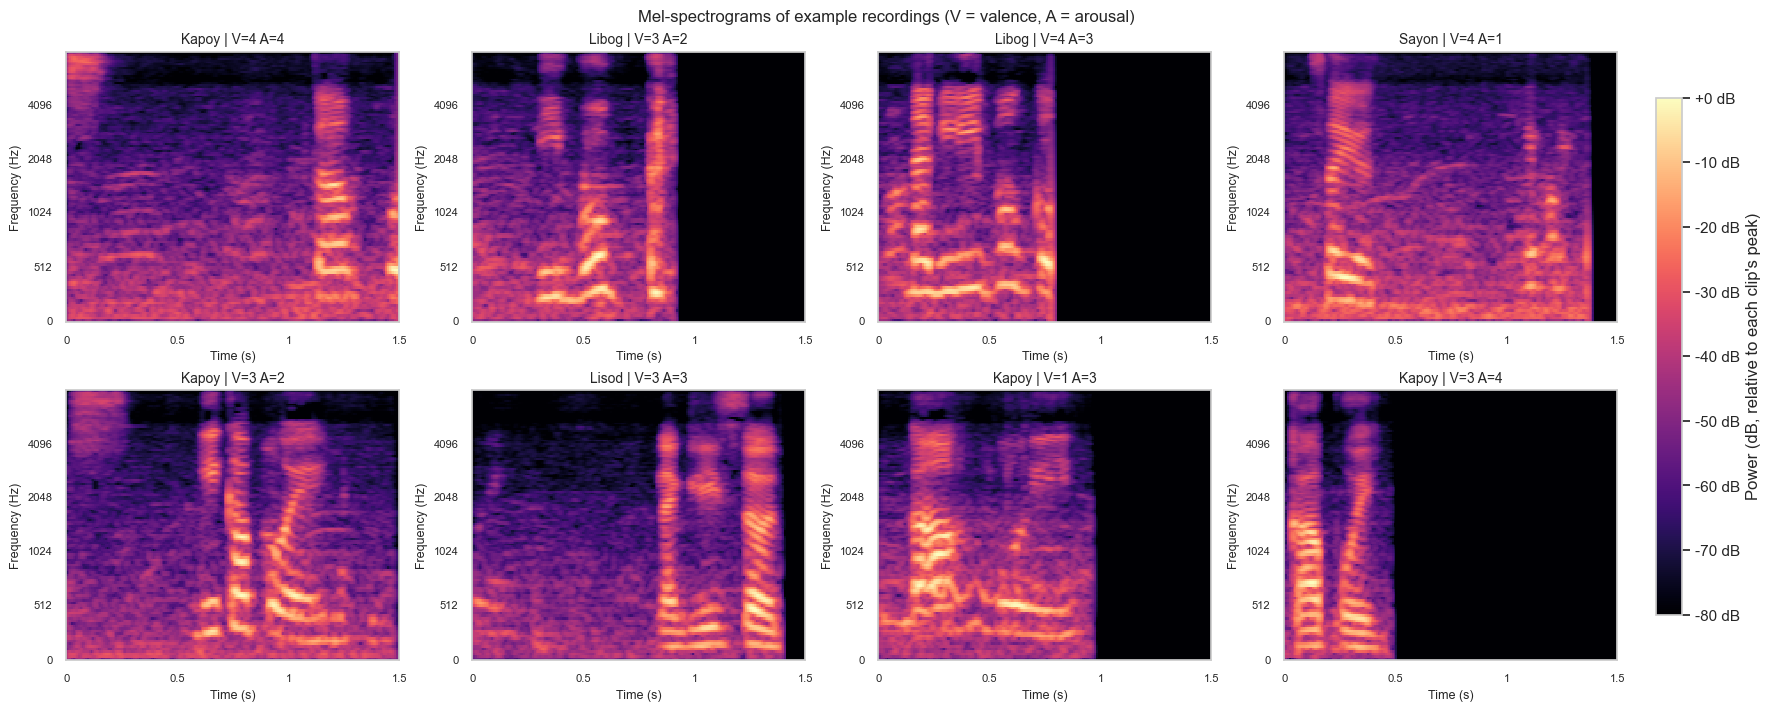

saved 30 labelled spectrograms to: Results\spectrograms_labelled


In [10]:
# ===================== AUDIO FEATURES + LABELLED SPECTROGRAM SUMMARY =====================
# Replaces the "4. Audio features" code cell in the notebook.
# Feature extraction and the CNN-input spectrogram images are UNCHANGED, so your model results stay the same.
# New: a labelled summary figure (time axis, frequency axis, colour bar) saved to the Results folder.

import math

import librosa.display          # needed for specshow (axis labels)

RESULTS_DIR = Path("Results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)


def load_audio(path):
    y, _ = librosa.load(path, sr=SR, mono=True)
    y, _ = librosa.effects.trim(y, top_db=25)
    if len(y) < 1024:
        y = np.pad(y, (0, 1024 - len(y)))
    return librosa.util.normalize(y)


def summarize(x, name):
    return {f"{name}_mean": float(np.mean(x)), f"{name}_std": float(np.std(x))}


def handcrafted_features(y):
    f = {"duration": len(y) / SR}
    # temporal / rhythm characteristics (Section XIV)
    segs = librosa.effects.split(y, top_db=30)
    f["n_segments"] = len(segs)
    f["active_ratio"] = float(sum(e - s for s, e in segs) / len(y))
    rms0 = librosa.feature.rms(y=y)[0]
    f["rms_peak_pos"] = float(np.argmax(rms0) / max(len(rms0) - 1, 1))
    f0, voiced, _ = librosa.pyin(y, fmin=65, fmax=500, sr=SR)
    f0v = f0[~np.isnan(f0)]
    if len(f0v) > 0:
        f.update({"f0_mean": f0v.mean(), "f0_std": f0v.std(), "f0_range": f0v.max() - f0v.min()})
    else:
        f.update({"f0_mean": 0.0, "f0_std": 0.0, "f0_range": 0.0})
    f["voiced_ratio"] = float(np.mean(voiced))
    rms = librosa.feature.rms(y=y)[0]
    f.update(summarize(rms, "rms")); f["rms_max"] = float(rms.max())
    f.update(summarize(librosa.feature.zero_crossing_rate(y)[0], "zcr"))
    f.update(summarize(librosa.feature.spectral_centroid(y=y, sr=SR)[0], "centroid"))
    mfcc = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=13)
    d1 = librosa.feature.delta(mfcc, width=5, mode="nearest")
    d2 = librosa.feature.delta(mfcc, order=2, width=5, mode="nearest")
    for i in range(13):
        f.update(summarize(mfcc[i], f"mfcc{i}"))
        f[f"dmfcc{i}_std"] = float(np.std(d1[i]))
        f[f"ddmfcc{i}_std"] = float(np.std(d2[i]))
    return f


def make_spectrogram(y, out_path):
    """Plain image (no axes) that is fed to the CNN. Do not add axes here."""
    n = int(CLIP_SEC * SR)
    y = y[:n] if len(y) >= n else np.pad(y, (0, n - len(y)))
    S = librosa.feature.melspectrogram(y=y, sr=SR, n_fft=1024, hop_length=128, n_mels=N_MELS)
    S_db = librosa.power_to_db(S, ref=np.max)
    S_norm = (S_db - S_db.min()) / (S_db.max() - S_db.min() + 1e-9)
    rgb = (matplotlib.colormaps["magma"](S_norm)[..., :3] * 255).astype(np.uint8)
    Image.fromarray(np.flipud(rgb)).resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR).save(out_path)
    return str(out_path)


hand_rows, img_paths, audio_cache = [], [], {}
for i, r in df.iterrows():
    y = load_audio(r["path"])
    audio_cache[i] = y                                   # kept only to draw the labelled figure below
    hand_rows.append(handcrafted_features(y))
    img_paths.append(make_spectrogram(y, IMG_DIR / (Path(r["file"]).stem + ".png")))

hand = pd.DataFrame(hand_rows).fillna(0.0)
X_hand = hand.values
print("Handcrafted audio features:", X_hand.shape)
hand.assign(file=df["file"]).to_csv(OUT_DIR / "acoustic_features.csv", index=False)

# ---------------- labelled spectrogram summary figure ----------------
N_SHOW = 8          # how many recordings to show
SHOW_WORD = None    # e.g. "Kapoy" to show only that word, sorted by valence (same-word comparison); None = first N_SHOW

show_idx = df.index.tolist()
if SHOW_WORD:
    show_idx = df[df["word"] == SHOW_WORD].sort_values("valence").index.tolist()
show_idx = show_idx[:N_SHOW]

if not show_idx:
    print(f"No recordings found for SHOW_WORD = {SHOW_WORD!r}")
else:
    ncols = 4
    nrows = math.ceil(len(show_idx) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.4 * ncols, 3.5 * nrows),
                             squeeze=False, constrained_layout=True)
    n_samples = int(CLIP_SEC * SR)
    img = None
    for ax in axes.ravel():
        ax.set_visible(False)
    for ax, i in zip(axes.ravel(), show_idx):
        ax.set_visible(True)
        y = audio_cache[i]
        y = y[:n_samples] if len(y) >= n_samples else np.pad(y, (0, n_samples - len(y)))
        S = librosa.feature.melspectrogram(y=y, sr=SR, n_fft=1024, hop_length=128, n_mels=N_MELS)
        S_db = librosa.power_to_db(S, ref=np.max)
        img = librosa.display.specshow(S_db, sr=SR, hop_length=128, x_axis="time", y_axis="mel",
                                       fmax=SR / 2, cmap="magma", vmin=-80, vmax=0, ax=ax)
        r = df.loc[i]
        ax.set_title(f"{r['word']} | V={r['valence']} A={r['arousal']}", fontsize=10)
        ax.set_xlabel("Time (s)", fontsize=9)
        ax.set_ylabel("Frequency (Hz)", fontsize=9)
        ax.tick_params(labelsize=8)
    fig.colorbar(img, ax=axes.ravel().tolist(), shrink=0.85, pad=0.02,
                 label="Power (dB, relative to each clip's peak)", format="%+.0f dB")
    fig.suptitle("Mel-spectrograms of example recordings (V = valence, A = arousal)", fontsize=12)

    out_name = f"spectrogram_examples_{SHOW_WORD.lower()}.png" if SHOW_WORD else "spectrogram_examples.png"
    fig.savefig(RESULTS_DIR / out_name, dpi=300, bbox_inches="tight")     # save BEFORE plt.show()
    print("saved:", RESULTS_DIR / out_name)
    plt.show()


# ---------------- one labelled spectrogram per recording (with axes) ----------------
# Saved to Results/spectrograms_labelled/. These are for figures and the report only;
# the plain images in outputs/spectrograms/ (no axes) remain the CNN input.
LABELLED_DIR = RESULTS_DIR / "spectrograms_labelled"
LABELLED_DIR.mkdir(parents=True, exist_ok=True)

n_samples = int(CLIP_SEC * SR)
for i, r in df.iterrows():
    y = audio_cache[i]
    y = y[:n_samples] if len(y) >= n_samples else np.pad(y, (0, n_samples - len(y)))
    S_db = librosa.power_to_db(
        librosa.feature.melspectrogram(y=y, sr=SR, n_fft=1024, hop_length=128, n_mels=N_MELS), ref=np.max)

    fig, ax = plt.subplots(figsize=(6.5, 4.2), constrained_layout=True)
    img = librosa.display.specshow(S_db, sr=SR, hop_length=128, x_axis="time", y_axis="mel",
                                   fmax=SR / 2, cmap="magma", vmin=-80, vmax=0, ax=ax)
    ax.set_title(f"{r['word']} | V={r['valence']} A={r['arousal']}\n{Path(r['file']).stem}", fontsize=11)
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Frequency (Hz)")
    fig.colorbar(img, ax=ax, label="Power (dB, relative to clip's peak)", format="%+.0f dB")
    fig.savefig(LABELLED_DIR / f"{Path(r['file']).stem}.png", dpi=200, bbox_inches="tight")
    plt.close(fig)                       # close so 30+ figures are not kept in memory or displayed

print(f"saved {len(df)} labelled spectrograms to: {LABELLED_DIR}")

### Audio data quality report (deliverable 5)
Checks each original WAV for length, level, clipping, and silence. Review flagged files and decide whether they are valid recordings.

In [25]:
qa_rows = []
for i, r in df.iterrows():
    y0, sr0 = librosa.load(r["path"], sr=None, mono=False)
    n_ch = 1 if y0.ndim == 1 else y0.shape[0]
    y1 = y0 if y0.ndim == 1 else y0.mean(axis=0)
    dur = len(y1) / sr0
    peak = float(np.max(np.abs(y1)))
    clip = float(np.mean(np.abs(y1) >= 0.99))
    rms_db = float(20 * np.log10(np.sqrt(np.mean(y1 ** 2)) + 1e-9))
    segs = librosa.effects.split(y1, top_db=30)
    active = float(sum(e - s for s, e in segs) / len(y1)) if len(y1) else 0.0
    flags = []
    if dur < 0.3: flags.append("very short")
    if dur > 5: flags.append("long (may contain extra speech)")
    if peak < 0.05: flags.append("very quiet")
    if clip > 0.001: flags.append("clipping")
    if active < 0.1: flags.append("mostly silence")
    qa_rows.append({"file": r["file"], "sample_rate": sr0, "channels": n_ch, "duration_s": round(dur, 2),
                    "peak": round(peak, 3), "rms_dB": round(rms_db, 1), "clipping_frac": round(clip, 4),
                    "active_ratio": round(active, 2), "flags": "; ".join(flags)})
qa_audio = pd.DataFrame(qa_rows)
qa_audio.to_csv(OUT_DIR / "audio_quality_report.csv", index=False)
print("Sample rates present:", sorted(qa_audio["sample_rate"].unique()))
display(qa_audio.describe().round(2))
print("Flagged recordings:")
display(qa_audio[qa_audio["flags"] != ""])

Sample rates present: [np.int64(192000)]


,sample_rate,channels,duration_s,peak,rms_dB,clipping_frac,active_ratio
count,30.0,30.0,30.00,30.00,30.00,30.0,30.00
mean,192000.0,2.0,1.24,0.29,-29.37,0.0,0.67
std,0.0,0.0,0.31,0.06,1.24,0.0,0.23
min,192000.0,2.0,0.68,0.19,-31.60,0.0,0.21
25%,192000.0,2.0,0.98,0.25,-30.00,0.0,0.46
50%,192000.0,2.0,1.18,0.27,-29.65,0.0,0.68
75%,192000.0,2.0,1.46,0.33,-28.45,0.0,0.90
max,192000.0,2.0,2.01,0.41,-26.90,0.0,0.99


Flagged recordings:


,file,sample_rate,channels,duration_s,peak,rms_dB,clipping_frac,active_ratio,flags


### RQ3: acoustic characteristics by self-reported affect (descriptive)
Mean and standard deviation of key acoustic features per self-reported class, with boxplots. p-values are Mann-Whitney tests, **uncorrected and exploratory** (many comparisons, small n); do not claim significance from them.


=== valence_class (n per class: {'non-positive': 18, 'positive': 12}) ===


,feature,non-positive mean (sd),positive mean (sd),p (uncorrected)
0,f0_mean,205.807 (55.592),204.942 (69.136),0.816
1,f0_std,36.959 (35.615),35.531 (35.732),0.949
2,rms_mean,0.122 (0.034),0.101 (0.030),0.072
3,zcr_mean,0.105 (0.048),0.103 (0.037),0.849
4,duration,0.844 (0.299),1.088 (0.452),0.156
5,active_ratio,0.980 (0.076),0.977 (0.068),0.694


saved: Results\rq3_valence_class_acoustic_boxplots.png


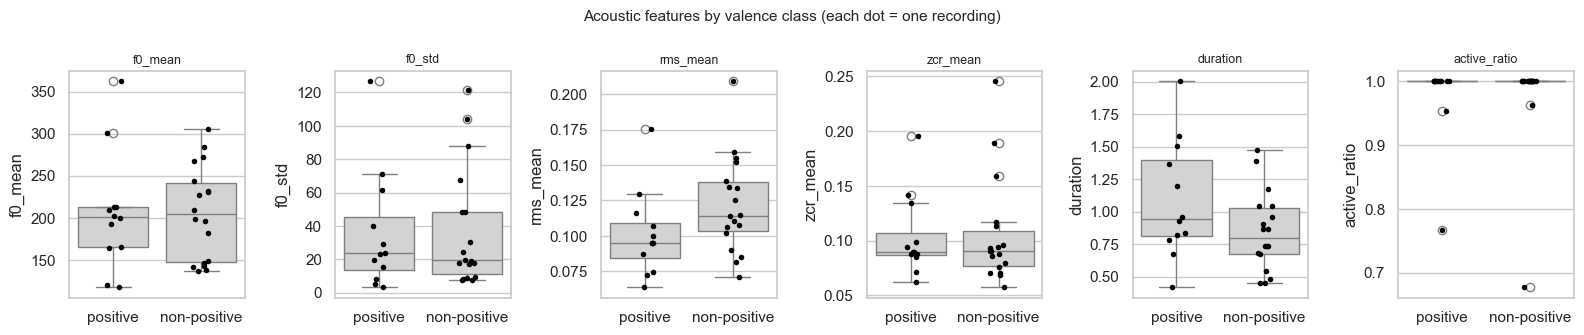


=== arousal_class (n per class: {'low-mod': 20, 'high': 10}) ===


,feature,high mean (sd),low-mod mean (sd),p (uncorrected)
0,f0_mean,214.867 (77.340),200.757 (51.279),0.775
1,f0_std,43.948 (43.391),32.607 (30.625),0.676
2,rms_mean,0.114 (0.044),0.113 (0.028),0.582
3,zcr_mean,0.107 (0.040),0.102 (0.045),0.644
4,duration,0.997 (0.491),0.914 (0.323),0.809
5,active_ratio,1.000 (0.000),0.968 (0.086),0.147


saved: Results\rq3_arousal_class_acoustic_boxplots.png


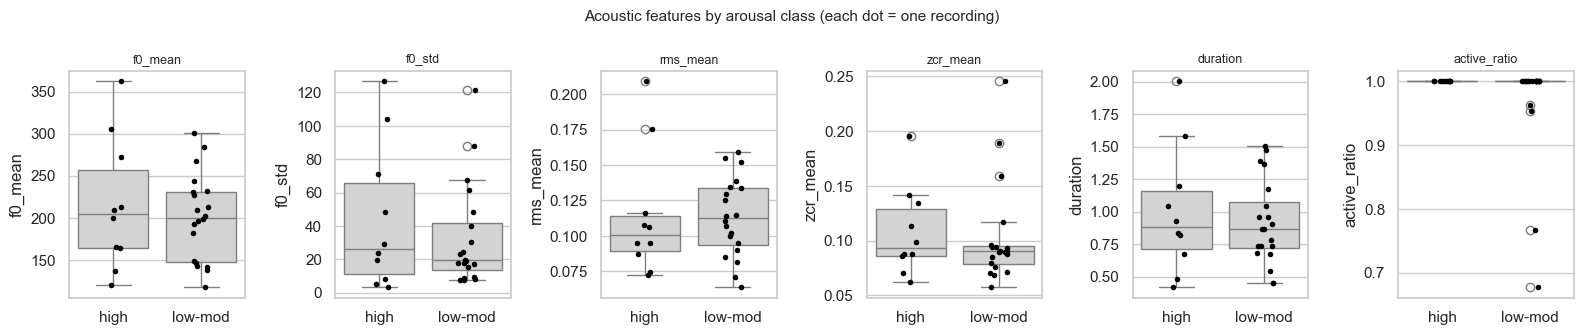

In [11]:
# ===================== RQ3: acoustic characteristics by self-reported affect =====================
# Descriptive comparison. p-values are Mann-Whitney tests, UNCORRECTED and exploratory (small n, many comparisons).
# Saves the figures (PNG) and the tables (CSV) to the Results folder.

from pathlib import Path

from scipy.stats import mannwhitneyu

RESULTS_DIR = Path("Results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

KEY_AUDIO = ["f0_mean", "f0_std", "rms_mean", "zcr_mean", "duration", "active_ratio"]

for target in ["valence_class", "arousal_class"]:
    d = hand[KEY_AUDIO].copy()
    d[target] = df[target].values
    classes = sorted(d[target].unique())
    rows = []
    for fcol in KEY_AUDIO:
        a, b = [d.loc[d[target] == k, fcol].values for k in classes[:2]]
        p = mannwhitneyu(a, b).pvalue if len(a) > 1 and len(b) > 1 else np.nan
        rows.append({"feature": fcol,
                     **{f"{k} mean (sd)": f"{d.loc[d[target] == k, fcol].mean():.3f} ({d.loc[d[target] == k, fcol].std():.3f})"
                        for k in classes},
                     "p (uncorrected)": round(p, 3)})

    tbl = pd.DataFrame(rows)
    print(f"\n=== {target} (n per class: {d[target].value_counts().to_dict()}) ===")
    display(tbl)
    tbl.to_csv(RESULTS_DIR / f"rq3_{target}_acoustic_comparison.csv", index=False, encoding="utf-8")

    fig, axes = plt.subplots(1, len(KEY_AUDIO), figsize=(16, 3.4))
    for ax, fcol in zip(axes, KEY_AUDIO):
        sns.boxplot(data=d, x=target, y=fcol, ax=ax, color="lightgray")
        sns.stripplot(data=d, x=target, y=fcol, ax=ax, color="black", size=4)
        ax.set_xlabel(""); ax.set_title(fcol, fontsize=9)
    fig.suptitle(f"Acoustic features by {target.replace('_', ' ')} (each dot = one recording)", fontsize=11)
    plt.tight_layout()
    out_path = RESULTS_DIR / f"rq3_{target}_acoustic_boxplots.png"
    fig.savefig(out_path, dpi=300, bbox_inches="tight")      # save BEFORE plt.show()
    print("saved:", out_path)
    plt.show()

In [12]:
import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display # Only needed if running outside Jupyter

# --- 1. SETUP MISSING DATA (Replace this with your actual data) ---
# Simulating the 'hand' DataFrame (your audio features)
KEY = ["duration", "f0_mean", "f0_std", "f0_range", "voiced_ratio", "rms_mean", "rms_max",
       "zcr_mean", "centroid_mean", "n_segments", "active_ratio", "rms_peak_pos"]
hand = pd.DataFrame(np.random.rand(50, len(KEY)), columns=KEY)

# Simulating the 'df' DataFrame (your target labels)
# Note: 'hand' and 'df' must have the same number of rows
df = pd.DataFrame({
    "valence_class": np.random.choice(["Positive", "Negative", "Neutral"], 50),
    "arousal_class": np.random.choice(["High", "Low"], 50)
})
# ------------------------------------------------------------------

# --- 2. YOUR CODE ---
RESULTS_DIR = Path("RESULTS") 
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# 1. Overall descriptive statistics for every audio feature
audio_desc = hand.describe().T.round(3)
display(audio_desc) # Use print(audio_desc) if not using Jupyter
audio_desc.to_csv(RESULTS_DIR / "audio_descriptive_statistics.csv", encoding="utf-8")

# 2. Key features only, by self-reported class (mean and sd)
for target in ["valence_class", "arousal_class"]:
    # Groups the 'hand' features by the corresponding labels in 'df'
    t = hand[KEY].groupby(df[target].values).agg(["mean", "std"]).round(3).T
    
    print(f"\n--- Statistics by {target} ---")
    display(t) # Use print(t) if not using Jupyter
    t.to_csv(RESULTS_DIR / f"audio_descriptive_by_{target}.csv", encoding="utf-8")

,count,mean,std,min,25%,50%,75%,max
duration,50.0,0.491,0.308,0.006,0.279,0.422,0.805,0.955
f0_mean,50.0,0.544,0.296,0.009,0.283,0.616,0.779,0.963
f0_std,50.0,0.505,0.309,0.012,0.231,0.498,0.746,0.987
f0_range,50.0,0.519,0.269,0.017,0.330,0.551,0.722,1.000
voiced_ratio,50.0,0.498,0.320,0.005,0.193,0.515,0.766,0.997
rms_mean,50.0,0.495,0.285,0.023,0.282,0.494,0.701,0.980
rms_max,50.0,0.521,0.291,0.034,0.325,0.538,0.766,0.991
zcr_mean,50.0,0.586,0.282,0.081,0.338,0.602,0.838,0.993
centroid_mean,50.0,0.505,0.310,0.007,0.260,0.564,0.768,0.964
n_segments,50.0,0.492,0.305,0.024,0.228,0.500,0.758,0.990



--- Statistics by valence_class ---


Negative  Neutral  Positive
duration      mean     0.450    0.516     0.522
              std      0.314    0.325     0.301
f0_mean       mean     0.535    0.519     0.574
              std      0.275    0.342     0.299
f0_std        mean     0.578    0.392     0.505
              std      0.323    0.321     0.275
f0_range      mean     0.514    0.535     0.512
              std      0.285    0.214     0.301
voiced_ratio  mean     0.518    0.410     0.543
              std      0.305    0.326     0.339
rms_mean      mean     0.498    0.442     0.531
              std      0.295    0.316     0.258
rms_max       mean     0.568    0.544     0.447
              std      0.271    0.253     0.340
zcr_mean      mean     0.538    0.557     0.664
              std      0.312    0.298     0.225
centroid_mean mean     0.540    0.475     0.488
              std      0.345    0.236     0.329
n_segments    mean     0.416    0.518     0.561
              std      0.289    0.351     0.283
active_ratio  mean     0.452    0.357     0.536
              std      0.312    0.274     0.280
rms_peak_pos  mean     0.368    0.364     0.538
              std      0.304    0.321     0.293


--- Statistics by arousal_class ---


High    Low
duration      mean  0.533  0.439
              std   0.272  0.348
f0_mean       mean  0.523  0.570
              std   0.320  0.268
f0_std        mean  0.499  0.512
              std   0.318  0.305
f0_range      mean  0.570  0.453
              std   0.238  0.297
voiced_ratio  mean  0.477  0.526
              std   0.340  0.299
rms_mean      mean  0.490  0.500
              std   0.276  0.302
rms_max       mean  0.575  0.452
              std   0.288  0.287
zcr_mean      mean  0.629  0.531
              std   0.302  0.249
centroid_mean mean  0.457  0.567
              std   0.300  0.318
n_segments    mean  0.523  0.452
              std   0.331  0.270
active_ratio  mean  0.446  0.469
              std   0.316  0.270
rms_peak_pos  mean  0.483  0.351
              std   0.299  0.314

### Spectrogram embeddings (frozen pretrained ResNet18)

In [27]:
net = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
net.fc = torch.nn.Identity()
net.eval()
tf = T.Compose([T.ToTensor(), T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])])
with torch.no_grad():
    X_cnn = np.vstack([net(tf(Image.open(p).convert("RGB")).unsqueeze(0)).squeeze(0).numpy() for p in img_paths])
print("Spectrogram CNN embeddings:", X_cnn.shape)
np.save(OUT_DIR / "cnn_embeddings.npy", X_cnn)

Spectrogram CNN embeddings: (30, 512)


## 5. Face features from video
MediaPipe Face Landmarker returns 52 **blendshape scores** per frame (for example `browInnerUp`, `mouthSmileLeft`, `eyeSquintLeft`). Each frame is analysed in memory and discarded. Per video we keep the mean, std, and max of each score.

**Important confound:** the participant is *speaking a word*, so jaw and mouth blendshapes mostly reflect which word was said, not how the participant feels. The same issue the project sheet raises for text applies here. We therefore build two face feature sets: all blendshapes, and a version with articulation-related blendshapes removed. Smile and frown blendshapes are kept.

In [28]:
MODEL_PATH = MODEL_DIR / "face_landmarker.task"
if not MODEL_PATH.exists():
    url = "https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task"
    urllib.request.urlretrieve(url, MODEL_PATH)

detector = vision.FaceLandmarker.create_from_options(vision.FaceLandmarkerOptions(
    base_options=mp_python.BaseOptions(model_asset_path=str(MODEL_PATH)),
    output_face_blendshapes=True, num_faces=1, running_mode=vision.RunningMode.IMAGE))


def face_blendshapes(video_path, t_start=np.nan, t_end=np.nan):
    cap = cv2.VideoCapture(str(video_path))
    fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    step = max(int(round(fps / FACE_FPS)), 1)
    scores, n_sampled, idx = [], 0, 0
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        t = idx / fps
        in_window = (np.isnan(t_start) or t >= t_start) and (np.isnan(t_end) or t <= t_end)
        if idx % step == 0 and in_window:
            n_sampled += 1
            rgb = np.ascontiguousarray(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
            res = detector.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb))
            if res.face_blendshapes:
                scores.append({c.category_name: c.score for c in res.face_blendshapes[0]})
        idx += 1
    cap.release()
    return scores, n_sampled


face_rows, qc_rows = [], []
for i, r in df.iterrows():
    if r["video_path"] is None:
        face_rows.append({}); qc_rows.append({"file": r["file"], "frames": 0, "detected": 0, "rate": 0.0})
        continue
    scores, n = face_blendshapes(r["video_path"], r["v_start"], r["v_end"])
    qc_rows.append({"file": r["file"], "frames": n, "detected": len(scores),
                    "rate": len(scores) / n if n else 0.0})
    if not scores:
        face_rows.append({}); continue
    s = pd.DataFrame(scores).drop(columns=["_neutral"], errors="ignore")
    feats = {}
    for c in s.columns:
        feats[f"bs_{c}_mean"] = s[c].mean()
        feats[f"bs_{c}_std"] = s[c].std(ddof=0)
        feats[f"bs_{c}_max"] = s[c].max()
    face_rows.append(feats)

face_df = pd.DataFrame(face_rows)          # NaN rows = no face found (imputed inside CV folds)
qc = pd.DataFrame(qc_rows)
print("Face feature matrix:", face_df.shape)
display(qc.describe().round(2))
low = qc[qc["rate"] < MIN_DETECTION_RATE]
print(f"Videos with face detected in < {MIN_DETECTION_RATE:.0%} of frames: {len(low)}")
display(low)
qc.to_csv(OUT_DIR / "face_quality_report.csv", index=False)
face_df.assign(file=df["file"]).to_csv(OUT_DIR / "face_features.csv", index=False)

Face feature matrix: (30, 153)


,frames,detected,rate
count,30.00,30.00,30.0
mean,11.60,11.60,1.0
std,3.29,3.29,0.0
min,4.00,4.00,1.0
25%,10.00,10.00,1.0
50%,11.00,11.00,1.0
75%,14.00,14.00,1.0
max,21.00,21.00,1.0


Videos with face detected in < 50% of frames: 0


,file,frames,detected,rate


## 6. Assemble feature blocks

In [29]:
ARTICULATION_PREFIXES = ("jaw", "mouthClose", "mouthFunnel", "mouthPucker", "mouthRoll", "mouthShrug",
                         "mouthLowerDown", "mouthUpperUp", "mouthLeft", "mouthRight", "tongue")


def bs_name(col):
    return col[3:].rsplit("_", 1)[0]


face_cols = list(face_df.columns)
X_face = face_df.values.astype(float)

X_all = np.hstack([X_hand, X_cnn, X_face])
h, c, f = X_hand.shape[1], X_cnn.shape[1], X_face.shape[1]
BLOCKS = {
    "hand": list(range(0, h)),
    "cnn": list(range(h, h + c)),
    "face_all": list(range(h + c, h + c + f)),
    "face_noart": [h + c + k for k, col in enumerate(face_cols) if not bs_name(col).startswith(ARTICULATION_PREFIXES)],
}
print({k: len(v) for k, v in BLOCKS.items()})

{'hand': 67, 'cnn': 512, 'face_all': 153, 'face_noart': 102}


In [42]:
# ===================== EXPORT THE THREE DATASETS =====================
# Paste this as a NEW CELL right after "6. Assemble feature blocks" in bisaya_multimodal_ser_v2.ipynb.
# Needs these variables from earlier cells: df, hand, face_df, qc, X_cnn, raw_meta, OUT_DIR, COL_FILE.
#
# Writes to outputs/datasets/:
#   audio_feature_dataset.csv       metadata + audio features
#   facial_feature_dataset.csv      metadata + face features + face quality columns
#   multimodal_dataset.csv          metadata + audio features + face features
#   data_dictionary.csv             every column and which group it belongs to

DATA_DIR = OUT_DIR / "datasets"
DATA_DIR.mkdir(parents=True, exist_ok=True)

INCLUDE_CNN_EMBEDDINGS = False   # True adds 512 spectrogram-embedding columns to the multimodal file

# ---- 1. Metadata / keys (identical in all three files, same row order) ----
lookup = raw_meta.rename(columns={COL_FILE: "file"}).set_index("file")


def from_meta(col):
    return df["file"].map(lookup[col]) if col in lookup.columns else np.nan


meta = pd.DataFrame({
    "participant_code": df["participant"].values,
    "audio_filename": df["file"].values,
    "video_filename": [Path(p).name if isinstance(p, str) else "" for p in df["video_path"]],
    "year_level": from_meta("Year Level").values,
    "class_activity": from_meta("Class Activity").values,
    "session": from_meta("Session").values,
    "spoken_word": df["word"].values,
    "self_reported_feeling": from_meta("Self-Reported Feeling").values,
    "valence": df["valence"].values,
    "arousal": df["arousal"].values,
    "valence_class": df["valence_class"].values,
    "arousal_class": df["arousal_class"].values,
})

# ---- 2. Feature groups with prefixes so columns never collide ----
audio_feats = hand.add_prefix("aud_").reset_index(drop=True)
face_feats = face_df.add_prefix("face_").reset_index(drop=True)
face_qc = pd.DataFrame({
    "face_frames_analysed": qc["frames"].values,
    "face_frames_detected": qc["detected"].values,
    "face_detection_rate": qc["rate"].round(3).values,
})

assert len(meta) == len(audio_feats) == len(face_feats) == len(face_qc), "row counts differ"
assert meta["audio_filename"].is_unique, "duplicate audio filenames"

# ---- 3. The three datasets ----
audio_dataset = pd.concat([meta, audio_feats], axis=1)
facial_dataset = pd.concat([meta, face_qc, face_feats], axis=1)
multi_parts = [meta, audio_feats, face_qc, face_feats]
if INCLUDE_CNN_EMBEDDINGS:
    multi_parts.insert(2, pd.DataFrame(X_cnn, columns=[f"cnn_{i}" for i in range(X_cnn.shape[1])]))
multimodal_dataset = pd.concat(multi_parts, axis=1)

audio_dataset.to_csv(DATA_DIR / "Group1_audio_feature_dataset.csv", index=False, encoding="utf-8")
facial_dataset.to_csv(DATA_DIR / "Group1_facial_feature_dataset.csv", index=False, encoding="utf-8")
multimodal_dataset.to_csv(DATA_DIR / "Group1_multimodal_dataset.csv", index=False, encoding="utf-8")

# ---- 4. Data dictionary ----
dd = [{"column": c, "group": "metadata (context and labels, NOT predictors)"} for c in meta.columns]
dd += [{"column": c, "group": "audio feature"} for c in audio_feats.columns]
dd += [{"column": c, "group": "face feature quality"} for c in face_qc.columns]
dd += [{"column": c, "group": "face feature (blendshape summary)"} for c in face_feats.columns]
if INCLUDE_CNN_EMBEDDINGS:
    dd += [{"column": f"cnn_{i}", "group": "spectrogram CNN embedding"} for i in range(X_cnn.shape[1])]
pd.DataFrame(dd).to_csv(DATA_DIR / "data_dictionary.csv", index=False, encoding="utf-8")

# ---- 5. Summary ----
print("Saved to", DATA_DIR)
for name, d in [("Group1_audio_feature_dataset", audio_dataset), ("Group1_facial_feature_dataset", facial_dataset),
                ("Group1_multimodal_dataset", multimodal_dataset)]:
    print(f"{name}: {d.shape[0]} rows x {d.shape[1]} columns")
no_face = int((face_qc["face_frames_detected"] == 0).sum())
print(f"Rows with no face detected (face features are blank): {no_face}")
display(multimodal_dataset.iloc[:3, :14])

Saved to RESULTS\datasets
Group1_audio_feature_dataset: 30 rows x 79 columns
Group1_facial_feature_dataset: 30 rows x 168 columns
Group1_multimodal_dataset: 30 rows x 235 columns
Rows with no face detected (face features are blank): 0


,participant_code,audio_filename,video_filename,year_level,class_activity,session,spoken_word,self_reported_feeling,valence,arousal,valence_class,arousal_class,aud_duration,aud_n_segments
0,Y1-001,Y1-001_Y1_AM_Kapoy.wav,Y1-001_Y1_AM_Kapoy.mp4,1st Year,Examination,Morning,Kapoy,Kapoy,4,4,positive,high,1.578688,1
1,Y1-002,Y1-002_Y1_AM_Libog.wav,Y1-002_Y1_AM_Libog.mp4,1st Year,Examination,Morning,Libog,Libog,3,2,non-positive,low-mod,0.906687,1
2,Y1-004,Y1-004_Y1_AM_Libog.wav,Y1-004_Y1_AM_Libog.mp4,1st Year,Examination,Morning,Libog,Nagmahay ko kay wala nako nakita ang bonus,4,3,positive,low-mod,0.778687,1


## 7. Models and fusion
- **Single**: one modality.
- **Early fusion**: scaler + PCA are applied **per modality block inside each training fold**, then the reduced blocks are concatenated and fed to one classifier.
- **Late fusion**: one logistic regression per modality; predicted probabilities are averaged.

Evaluation is leave-one-participant-out.

In [30]:
groups = df["participant"].values
splits = list(LeaveOneGroupOut().split(X_all, groups=groups))
print("Folds:", len(splits))


def block_pipe():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                         PCA(n_components=N_PCA, random_state=SEED))


def make_model(kind, block_names):
    ct = ColumnTransformer([(b, block_pipe(), BLOCKS[b]) for b in block_names])
    if kind == "LogReg":
        clf = LogisticRegression(C=0.5, max_iter=2000, class_weight="balanced")
    elif kind == "SVM":
        clf = SVC(kernel="rbf", C=1.0, class_weight="balanced")
    else:
        clf = RandomForestClassifier(n_estimators=100, max_depth=4, min_samples_leaf=2,
                                     class_weight="balanced", random_state=SEED)
    return make_pipeline(ct, clf)


def predict_oof(cfg, y):
    if cfg["model"] == "Baseline":
        return cross_val_predict(DummyClassifier(strategy="most_frequent"), np.zeros((len(y), 1)), y, cv=splits)
    if cfg["fusion"] == "late":
        probs = [cross_val_predict(make_model("LogReg", [b]), X_all, y, cv=splits, method="predict_proba")
                 for b in cfg["blocks"]]
        return np.unique(y)[np.mean(probs, axis=0).argmax(axis=1)]
    return cross_val_predict(make_model(cfg["model"], cfg["blocks"]), X_all, y, cv=splits)


EXPERIMENTS = [
    ("Audio: handcrafted", ["hand"], "single"),
    ("Audio: spectrogram CNN", ["cnn"], "single"),
    ("Face: all blendshapes", ["face_all"], "single"),
    ("Face: no articulation", ["face_noart"], "single"),
    ("Early: audio(hand) + face(no art)", ["hand", "face_noart"], "early"),
    ("Early: hand + CNN + face(no art)", ["hand", "cnn", "face_noart"], "early"),
    ("Late: audio(hand) + face(no art)", ["hand", "face_noart"], "late"),
    ("Late: hand + CNN + face(no art)", ["hand", "cnn", "face_noart"], "late"),
]

CONFIGS = [{"experiment": "Baseline (majority)", "blocks": [], "fusion": "none", "model": "Baseline"}]
for name, blocks, fusion in EXPERIMENTS:
    for m in (["LogReg"] if fusion == "late" else ["LogReg", "SVM", "RandomForest"]):
        CONFIGS.append({"experiment": name, "blocks": blocks, "fusion": fusion, "model": m})

results, all_preds = {}, {}
for target in ["valence_class", "arousal_class"]:
    y = df[target].values
    rows = []
    for k, cfg in enumerate(CONFIGS):
        pred = predict_oof(cfg, y)
        all_preds[(target, k)] = pred
        rows.append({"experiment": cfg["experiment"], "fusion": cfg["fusion"], "model": cfg["model"],
                     "accuracy": round(accuracy_score(y, pred), 3),
                     "macro_f1": round(f1_score(y, pred, average="macro"), 3), "cfg_id": k})
    results[target] = pd.DataFrame(rows).sort_values("macro_f1", ascending=False).reset_index(drop=True)
    print(f"\n===== {target} =====")
    display(results[target].drop(columns="cfg_id"))

pd.concat([r.assign(target=t) for t, r in results.items()]).drop(columns="cfg_id").to_csv(
    OUT_DIR / "model_results.csv", index=False)

Folds: 30

===== valence_class =====


Folds: 30

===== valence_class =====


,experiment,fusion,model,accuracy,macro_f1
0,Audio: handcrafted,single,LogReg,0.733,0.722
1,Face: all blendshapes,single,SVM,0.700,0.700
2,Audio: handcrafted,single,SVM,0.700,0.683
3,Audio: spectrogram CNN,single,LogReg,0.633,0.612
4,Late: hand + CNN + face(no art),late,LogReg,0.600,0.593
5,Early: audio(hand) + face(no art),early,LogReg,0.600,0.583
6,Late: audio(hand) + face(no art),late,LogReg,0.600,0.569
7,Face: all blendshapes,single,LogReg,0.567,0.562
8,Face: no articulation,single,LogReg,0.533,0.525
9,Audio: spectrogram CNN,single,SVM,0.533,0.514


Folds: 30

===== valence_class =====


,experiment,fusion,model,accuracy,macro_f1
0,Audio: handcrafted,single,LogReg,0.733,0.722
1,Face: all blendshapes,single,SVM,0.700,0.700
2,Audio: handcrafted,single,SVM,0.700,0.683
3,Audio: spectrogram CNN,single,LogReg,0.633,0.612
4,Late: hand + CNN + face(no art),late,LogReg,0.600,0.593
5,Early: audio(hand) + face(no art),early,LogReg,0.600,0.583
6,Late: audio(hand) + face(no art),late,LogReg,0.600,0.569
7,Face: all blendshapes,single,LogReg,0.567,0.562
8,Face: no articulation,single,LogReg,0.533,0.525
9,Audio: spectrogram CNN,single,SVM,0.533,0.514



===== arousal_class =====


,experiment,fusion,model,accuracy,macro_f1
0,Audio: spectrogram CNN,single,LogReg,0.600,0.550
1,Early: audio(hand) + face(no art),early,SVM,0.633,0.549
2,Face: all blendshapes,single,LogReg,0.567,0.542
3,Face: no articulation,single,LogReg,0.533,0.514
4,Early: hand + CNN + face(no art),early,LogReg,0.533,0.498
5,Face: no articulation,single,SVM,0.600,0.489
6,Face: all blendshapes,single,SVM,0.533,0.475
7,Audio: handcrafted,single,SVM,0.533,0.475
8,Audio: handcrafted,single,LogReg,0.500,0.471
9,Late: audio(hand) + face(no art),late,LogReg,0.500,0.471


### Confusion matrices and per-class metrics
Top row: best **audio-only** configuration (RQ4, protocol primary analysis). Bottom row: best configuration overall, including face. Rows are valence then arousal.


--- valence_class | audio-only | Audio: handcrafted (LogReg) ---
              precision    recall  f1-score   support

non-positive       0.78      0.78      0.78        18
    positive       0.67      0.67      0.67        12

    accuracy                           0.73        30
   macro avg       0.72      0.72      0.72        30
weighted avg       0.73      0.73      0.73        30


--- valence_class | overall | Audio: handcrafted (LogReg) ---
              precision    recall  f1-score   support

non-positive       0.78      0.78      0.78        18
    positive       0.67      0.67      0.67        12

    accuracy                           0.73        30
   macro avg       0.72      0.72      0.72        30
weighted avg       0.73      0.73      0.73        30


--- arousal_class | audio-only | Audio: spectrogram CNN (LogReg) ---
              precision    recall  f1-score   support

        high       0.40      0.40      0.40        10
     low-mod       0.70      0.70     


--- valence_class | audio-only | Audio: handcrafted (LogReg) ---
              precision    recall  f1-score   support

non-positive       0.78      0.78      0.78        18
    positive       0.67      0.67      0.67        12

    accuracy                           0.73        30
   macro avg       0.72      0.72      0.72        30
weighted avg       0.73      0.73      0.73        30


--- valence_class | overall | Audio: handcrafted (LogReg) ---
              precision    recall  f1-score   support

non-positive       0.78      0.78      0.78        18
    positive       0.67      0.67      0.67        12

    accuracy                           0.73        30
   macro avg       0.72      0.72      0.72        30
weighted avg       0.73      0.73      0.73        30


--- arousal_class | audio-only | Audio: spectrogram CNN (LogReg) ---
              precision    recall  f1-score   support

        high       0.40      0.40      0.40        10
     low-mod       0.70      0.70     

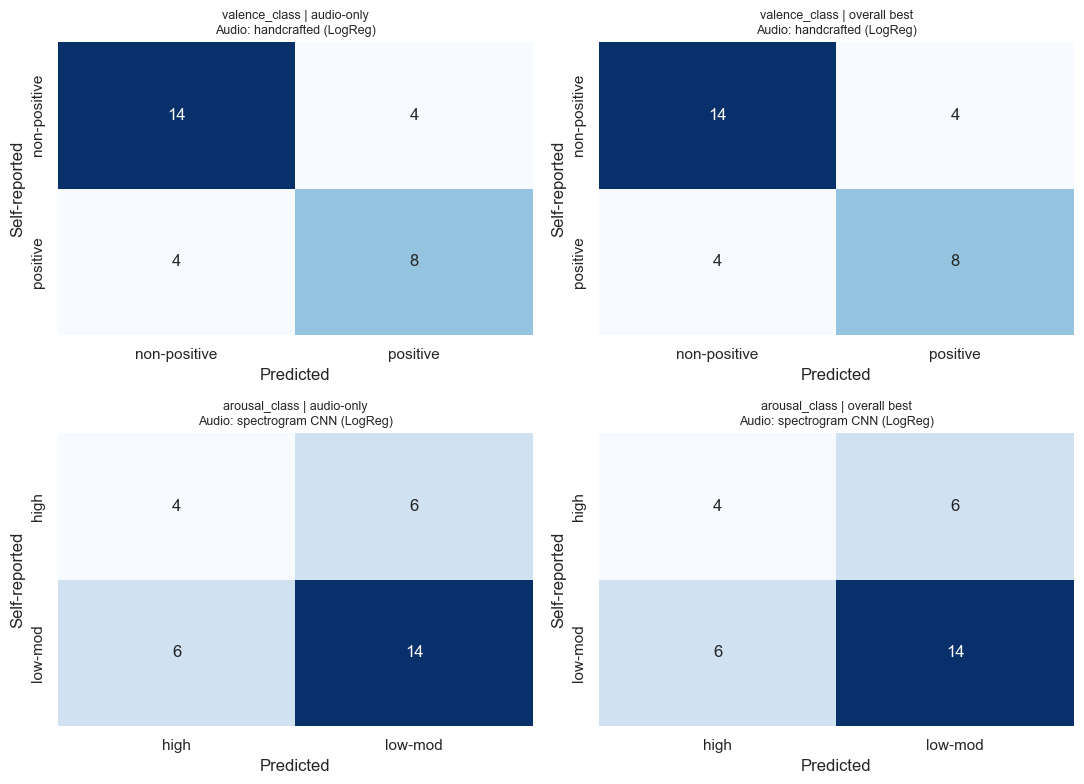

In [31]:
from sklearn.metrics import classification_report

targets = ["valence_class", "arousal_class"]


def best_of(target, audio_only):
    res = results[target]
    res = res[res["model"] != "Baseline"]
    if audio_only:
        res = res[res["cfg_id"].apply(lambda k: set(CONFIGS[int(k)]["blocks"]) <= {"hand", "cnn"})]
    return res.iloc[0]


fig, axes = plt.subplots(2, 2, figsize=(11, 8))
best_cfg = {}
for r_i, target in enumerate(targets):
    y = df[target].values
    labels = sorted(set(y))
    for c_i, audio_only in enumerate([True, False]):
        best = best_of(target, audio_only)
        k = int(best["cfg_id"])
        best_cfg[(target, audio_only)] = CONFIGS[k]
        pred = all_preds[(target, k)]
        cm = confusion_matrix(y, pred, labels=labels)
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels,
                    ax=axes[r_i][c_i], cbar=False)
        axes[r_i][c_i].set_title(f"{target} | {'audio-only' if audio_only else 'overall best'}\n"
                                 f"{best['experiment']} ({best['model']})", fontsize=9)
        axes[r_i][c_i].set_xlabel("Predicted"); axes[r_i][c_i].set_ylabel("Self-reported")
        print(f"\n--- {target} | {'audio-only' if audio_only else 'overall'} | {best['experiment']} ({best['model']}) ---")
        print(classification_report(y, pred, zero_division=0))
plt.tight_layout()
plt.savefig(OUT_DIR / "confusion_matrices.png", dpi=150)
plt.show()

## 8. Permutation test
Is the best configuration better than what shuffled labels would give? Note that choosing the best of many configurations makes this test somewhat optimistic; state that in the limitations.

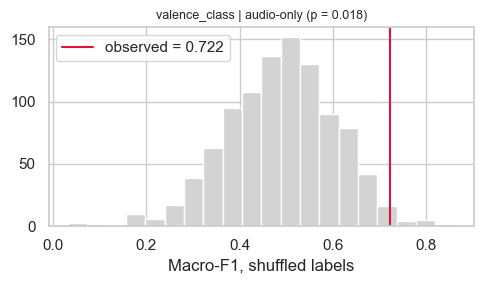

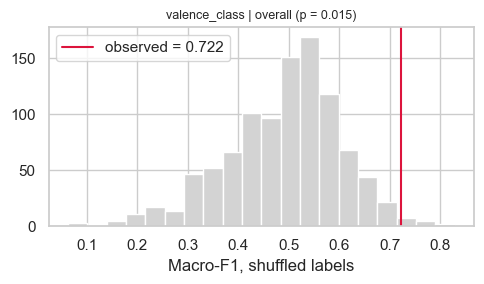

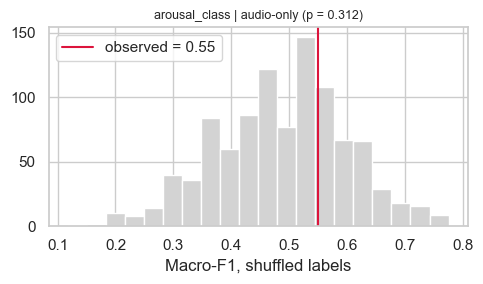

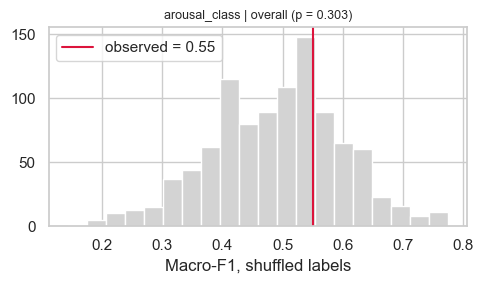

,target,scope,best,observed_macro_f1,baseline_macro_f1,chance_mean,p_value
0,valence_class,audio-only,Audio: handcrafted (LogReg),0.722,0.375,0.490,0.018
1,valence_class,overall,Audio: handcrafted (LogReg),0.722,0.375,0.490,0.015
2,arousal_class,audio-only,Audio: spectrogram CNN (LogReg),0.550,0.400,0.487,0.312
3,arousal_class,overall,Audio: spectrogram CNN (LogReg),0.550,0.400,0.490,0.303


In [43]:
N_PERM = 1000
rng = np.random.default_rng(SEED)
perm_summary = []
for (target, audio_only), cfg in best_cfg.items():
    y = df[target].values
    best = best_of(target, audio_only)
    observed = best["macro_f1"]
    base = results[target].query("model == 'Baseline'").iloc[0]["macro_f1"]
    null = []
    for _ in range(N_PERM):
        y_perm = rng.permutation(y)
        null.append(f1_score(y_perm, predict_oof(cfg, y_perm), average="macro"))
    null = np.array(null)
    p = (np.sum(null >= observed) + 1) / (N_PERM + 1)
    perm_summary.append({"target": target, "scope": "audio-only" if audio_only else "overall",
                         "best": f"{cfg['experiment']} ({cfg['model']})",
                         "observed_macro_f1": observed, "baseline_macro_f1": base,
                         "chance_mean": round(null.mean(), 3), "p_value": round(p, 3)})
    plt.figure(figsize=(5, 3))
    plt.hist(null, bins=20, color="lightgray")
    plt.axvline(observed, color="crimson", label=f"observed = {observed}")
    plt.title(f"{target} | {'audio-only' if audio_only else 'overall'} (p = {p:.3f})", fontsize=9)
    plt.xlabel("Macro-F1, shuffled labels"); plt.legend()
    plt.tight_layout(); plt.show()
perm_df = pd.DataFrame(perm_summary)
perm_df.to_csv(OUT_DIR / "permutation_tests.csv", index=False)
perm_df

## 9. Face descriptives (valence class)
Mean blendshape scores by self-reported valence class, articulation blendshapes excluded. Descriptive only; with n = 30 do not claim significance.

valence_class,non-positive,positive
browInnerUp,0.111,0.224
eyeLookUpLeft,0.159,0.070
eyeLookUpRight,0.153,0.065
eyeLookOutLeft,0.223,0.295
eyeLookInRight,0.227,0.298
browOuterUpLeft,0.194,0.258
eyeLookDownLeft,0.145,0.208
eyeLookDownRight,0.147,0.210
eyeSquintLeft,0.462,0.402
browOuterUpRight,0.122,0.169


valence_class,non-positive,positive
browInnerUp,0.111,0.224
eyeLookUpLeft,0.159,0.070
eyeLookUpRight,0.153,0.065
eyeLookOutLeft,0.223,0.295
eyeLookInRight,0.227,0.298
browOuterUpLeft,0.194,0.258
eyeLookDownLeft,0.145,0.208
eyeLookDownRight,0.147,0.210
eyeSquintLeft,0.462,0.402
browOuterUpRight,0.122,0.169


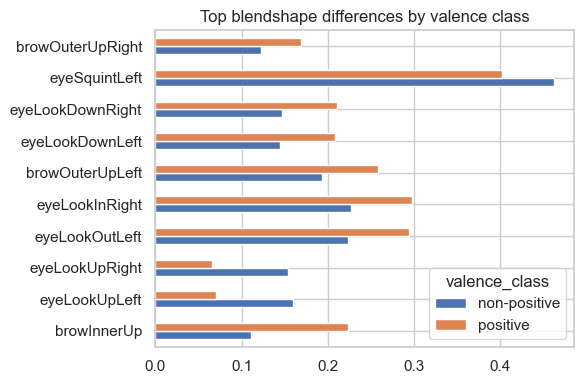

In [33]:
mean_cols = [col for col in face_cols if col.endswith("_mean") and not bs_name(col).startswith(ARTICULATION_PREFIXES)]
tmp = face_df[mean_cols].copy()
tmp["valence_class"] = df["valence_class"].values
g = tmp.groupby("valence_class")[mean_cols].mean().T
g["abs_diff"] = (g.get("positive", 0) - g.get("non-positive", 0)).abs()
top = g.sort_values("abs_diff", ascending=False).head(10).drop(columns="abs_diff")
top.index = [bs_name(i) for i in top.index]
display(top.round(3))
top.plot.barh(figsize=(6, 4)); plt.title("Top blendshape differences by valence class"); plt.tight_layout(); plt.show()

## 10. Lexically controlled analysis (descriptive)
Same spoken word, different self-reported affect. Audio features plus a smile score (mean of left and right mouth-smile). Because the word is held constant, articulation is constant too, which makes the face comparison fairer here.

In [34]:
KEY = ["f0_mean", "f0_std", "rms_mean", "rms_max", "zcr_mean", "duration"]
lex = pd.concat([df[["word", "valence_class"]], hand[KEY]], axis=1)
sm = [col for col in ["bs_mouthSmileLeft_mean", "bs_mouthSmileRight_mean"] if col in face_df.columns]
if sm:
    lex["smile"] = face_df[sm].mean(axis=1).values

counts = lex.groupby(["word", "valence_class"]).size().unstack(fill_value=0)
display(counts)
eligible = counts[(counts > 0).sum(axis=1) >= 2].index.tolist()
print("Words with both valence classes present:", eligible)
for w in eligible:
    print(f"\n--- {w} ---")
    display(lex[lex["word"] == w].groupby("valence_class").mean(numeric_only=True).round(3))

valence_class,non-positive,positive
word,,
Grabe,2,1
Kapoy,9,4
Libog,1,1
Lingaw,0,3
Lisod,3,0
Salamat,1,2
Sayon,2,1


Words with both valence classes present: ['Grabe', 'Kapoy', 'Libog', 'Salamat', 'Sayon']

--- Grabe ---


,f0_mean,f0_std,rms_mean,rms_max,zcr_mean,duration,smile
valence_class,,,,,,,
non-positive,185.141,7.387,0.118,0.282,0.092,0.656,0.305
positive,212.879,5.068,0.095,0.326,0.088,0.832,0.656



--- Kapoy ---


,f0_mean,f0_std,rms_mean,rms_max,zcr_mean,duration,smile
valence_class,,,,,,,
non-positive,203.267,42.147,0.115,0.278,0.085,0.900,0.179
positive,203.112,38.308,0.078,0.272,0.100,1.237,0.222


...

,f0_mean,f0_std,rms_mean,rms_max,zcr_mean,duration,smile
valence_class,,,,,,,
non-positive,267.546,30.382,0.134,0.349,0.079,0.907,0.592
positive,301.304,39.703,0.129,0.221,0.094,0.779,0.126



--- Salamat ---


,f0_mean,f0_std,rms_mean,rms_max,zcr_mean,duration,smile
valence_class,,,,,,,
non-positive,196.502,9.290,0.114,0.335,0.094,0.864,0.192
positive,204.634,24.342,0.102,0.269,0.165,1.467,0.362



--- Sayon ---


,f0_mean,f0_std,rms_mean,rms_max,zcr_mean,duration,smile
valence_class,,,,,,,
non-positive,226.378,61.05,0.145,0.327,0.151,0.608,0.432
positive,192.198,23.34,0.107,0.402,0.085,1.365,0.071


### Lexically controlled classification (Section XVII)
To hold the word constant statistically, each acoustic feature is centred **within each spoken word** (the word's mean is subtracted), so the model cannot use differences that only reflect which word was said. Then the same leave-one-participant-out evaluation is run. Words said by only one participant carry no information after centring. Exploratory only.

In [35]:
Xh = pd.DataFrame(X_hand, columns=hand.columns)
Xc = (Xh - Xh.groupby(df["word"].values).transform("mean")).values
lex_rows = []
for target in ["valence_class", "arousal_class"]:
    y = df[target].values
    pipe = make_pipeline(StandardScaler(), PCA(n_components=N_PCA, random_state=SEED),
                         LogisticRegression(C=0.5, max_iter=2000, class_weight="balanced"))
    pred = cross_val_predict(pipe, Xc, y, cv=splits)
    base_pred = cross_val_predict(DummyClassifier(strategy="most_frequent"), np.zeros((len(y), 1)), y, cv=splits)
    lex_rows.append({"target": target,
                     "word-centred audio macro-F1": round(f1_score(y, pred, average="macro"), 3),
                     "baseline macro-F1": round(f1_score(y, base_pred, average="macro"), 3),
                     "accuracy": round(accuracy_score(y, pred), 3)})
lex_cls = pd.DataFrame(lex_rows)
lex_cls.to_csv(OUT_DIR / "lexically_controlled_results.csv", index=False)
lex_cls

,target,word-centred audio macro-F1,baseline macro-F1,accuracy
0,valence_class,0.583,0.375,0.600
1,arousal_class,0.542,0.400,0.567


## Prototype recognition system (Section XX)
A prototype that takes one new WAV and returns the predicted valence and arousal class. It uses **audio only** (handcrafted features, logistic regression), trained on all participants. It is a demonstration for the class prototype, not a validated model: its reliable accuracy is the leave-one-participant-out result above, not performance on the training data.

In [ ]:
final_models = {t: make_model("LogReg", ["hand"]).fit(X_all, df[t].values)
                for t in ["valence_class", "arousal_class"]}


def predict_affect(wav_path):
    feats = pd.DataFrame([handcrafted_features(load_audio(wav_path))])[hand.columns].fillna(0.0).values[0]
    x = np.full((1, X_all.shape[1]), np.nan)
    x[0, BLOCKS["hand"]] = feats
    return {t: m.predict(x)[0] for t, m in final_models.items()}


# Example (replace with a real file path):
predict_affect("audio/Y1-027_Y1_PM_Lingaw.wav")

NameError: name 'make_model' is not defined

: 

## Interpretation checklist and limitations (deliverables 10 and 11)
**Interpretation**
- Does the best **audio-only** macro-F1 beat the majority baseline and the permutation chance level? (RQ4)
- Which model and feature set performed best, and by how much? (RQ5)
- Does adding face improve on audio alone? Report it only as an extension.
- Face (all) vs face (no articulation): a gap suggests the face scores reflect which word was said.
- Does the word-centred audio analysis still beat the baseline? If yes, how-it-is-spoken carries information beyond the word; if no, say so.

**Limitations to state**
- Fewer than the required 40 observations (report the actual number and why).
- One year level only, so Year Level x Affect cannot be examined by this group.
- One recording per participant; binarised ratings; ratings are self-report.
- Best configuration chosen on the same data used for evaluation (optimistic).
- Peak-normalised audio, so absolute loudness is not preserved; recording distance and microphone differences are not controlled.
- Face: lighting, camera angle, speaking-related facial movement, and detector performance; only if consent and approval cover video.
- Spoken words are unevenly distributed, so word effects cannot be fully separated from affect.